In [1]:
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import random
import pickle
import pandas as pd
import glob, os
from anndata import AnnData
from pathlib import Path
from diversity_curves.classifiers import *
from geosketch import gs
import networkx as nx

# Loading and preparing the data

Create subfolders in which the outputs will be saved.

In [2]:
results_path="./plots/"
if os.path.exists(results_path) == False:
    os.makedirs(results_path)
results_path="./accuracies/"
if os.path.exists(results_path) == False:
    os.makedirs(results_path)

## Loading the single-cell data

Make sure the preprocessed single cell datasets from [https://github.com/pqiu/Quantifying_clusterness_trajectoriness](https://github.com/pqiu/Quantifying_clusterness_trajectoriness) and the annotations are saved in `diversity_curves/data/sc/`.

In [3]:
path = "./../data/sc/real_data_dict.pkl"

with open(path, 'rb') as f:
    x = pickle.load(f)

types = pd.read_csv("./../data/sc/data_type.csv")

Extract the type of single-cell dataset and map the names onto trajectory-like or cluster-like annotations.

In [4]:
types_list = []
keys = x.keys()
for k in keys:
    typet = x[k]["data_type"]
    types_list.append(typet)

In [5]:
types_list_vals = [str(t) for t in types_list]
traj_types_to_type = {
    "cluster": "cluster like",
    "organ": "cluster like",
    "disconnected_graph": "cluster like",
    "tree": "trajectory like",
    "convergence": "trajectory like",
    "linear": "trajectory like",
    "cycle": "trajectory like",
    "acyclic_graph": "trajectory like",
    "bifurcation": "trajectory like",
    "multifurcation": "trajectory like"
}
traj_types_vals = pd.Series(types_list_vals).map(traj_types_to_type)

traj_types_to_type2 = {
    "cluster": "cluster",
    "organ": "cluster",
    "disconnected_graph": "cluster",
    "tree": "cluster",
    "convergence": "trajectory",
    "linear": "trajectory",
    "cycle": "trajectory",
    "acyclic_graph": "trajectory",
    "bifurcation": "trajectory",
    "multifurcation": "trajectory"
}
traj_types_vals2 = pd.Series(types_list_vals).map(traj_types_to_type2)

In [6]:
lables_t = []
for t in traj_types_vals:
    if "clust" in t:
        lables_t.append(0)
    else:
        lables_t.append(1)
lables_t = np.array(lables_t).flatten()

Load in the single-cell datasets as graphs as described in our manuscript.

In [7]:
n_obs = []
n_vars = []
names = []
types_list = []
G_nx_full =[]
keys = [k for k in x.keys()]
for i, k in enumerate(keys):
    tt =traj_types_vals2[i]
    name = k 
    print(name)
    typet = x[k]["data_type"]
    print(typet)
    data = x[k]["pca_data"]
    n_obs.append(data.shape[0])
    n_vars.append(data.shape[1])
    names.append(name)
    types_list.append(typet)
    N = 200
    try:
        sketch_index = gs(data, N, replace=False)
        data = data[sketch_index]
    except:
        print("Error in geosketch for dataset ", name)
        #X_sketch = pcs
    data_sketch = AnnData(data)
    sc.pp.neighbors(data_sketch, n_neighbors=10)
    #sc.tl.umap(data_sketch)
        
    graph = data_sketch.obsp['connectivities']
    nx_graph = nx.from_numpy_array(graph.toarray())
    data_norm = data_sketch.X
    for j in range(data_sketch.shape[0]):
        nx_graph.nodes[j]["feature"] = data_norm[j]
    G_nx_full.append(nx_graph)
    # pos = {i: data_sketch.obsm['X_umap'][i] for i in range(data_sketch.n_obs)}
    
    # if tt == "trajectory":
    #     node_color="tab:blue"
    # else:
    #     node_color="tab:orange"

aging-hsc-old_kowalczyk
linear
aging-hsc-young_kowalczyk
linear
blastocyst-monkey_nakamura
disconnected_graph
bone-marrow-mesenchyme-erythrocyte-differentiation_mca
linear
cell-cycle_buettner
cycle
cell-cycle_leng
cycle
cellbench-SC1_luyitian
bifurcation
Error in geosketch for dataset  cellbench-SC1_luyitian
cellbench-SC2_luyitian
bifurcation
Error in geosketch for dataset  cellbench-SC2_luyitian
cellbench-SC3_luyitian
bifurcation
Error in geosketch for dataset  cellbench-SC3_luyitian
cellbench-SC4_luyitian
bifurcation
Error in geosketch for dataset  cellbench-SC4_luyitian
cortical-interneuron-differentiation_frazer
multifurcation
dentate-gyrus-neurogenesis_hochgerner
linear
developing-dendritic-cells_schlitzer
linear
distal-lung-epithelium_treutlein
bifurcation
Error in geosketch for dataset  distal-lung-epithelium_treutlein
embronic-mesenchyme-neuron-differentiation_mca
tree
embryonic-mesenchyme-stromal-cell-cxcl14-cxcl12-axis_mca
linear
epiblast-monkey_nakamura
tree
Error in geosket

Create boolean vectors to later subset to datasets with gold starndard annotations as described in our manuscript.

In [8]:
summary = pd.read_excel("/home/limbeckkat/Code/mag_graph/data/sc/41587_2019_71_MOESM4_ESM.xlsx")
gold = summary[summary["standard"]=="gold"]
gold["id"] = [g.replace("real/gold/", "") for g in gold.id]
bol = pd.Series([n in gold.id.values for n in names])
bol2 = pd.Series([t=="cluster" for t in types_list_vals]) | pd.Series([t=="organ" for t in types_list_vals])
bol1 = bol | bol2

/tmp/ipykernel_1070090/4213499838.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  gold["id"] = [g.replace("real/gold/", "") for g in gold.id]


## Loading the graph embeddings

Extract the 5 geometric scores by Lim and Qiu computed as described in 
> H. S. Lim and P. Qiu. Quantifying the clusterness and trajectoriness of single-cell RNA-seq data. PLoS Computational Biology, 20(2):e1011866, 2024.

In [9]:
df_scores=[]
keys = x.keys()
for k in keys:
    row = x[k]["score"]
    df_scores.append(row)
df_scores = np.array(df_scores)

In [10]:
arrays={}
arrays["scores"] = df_scores
for i in range(df_scores.shape[1]):
    arrays["scores_"+str(i)] = df_scores[:,[i]]

Load the pre-computed graph embeddings previously saved in `diversity_curves/single_cell/results/`.

In [11]:
path = "./results"
toper_arrays_super=[]
toper_arrays_sub=[]
spread_arrays=[]
spread_names=[]
for csv in glob.glob(os.path.join(path, "*.csv")):
    name = str(Path(csv).stem)
    print(name)
    if ("time" in name) or ("result" in name):
        continue
    else:
        if "spread" in name:
            df = pd.read_csv(csv, index_col=0)
        else:
            df = pd.read_csv(csv, index_col=None)
        #print(df)
        arrays[name] = df.values
        if "toper" in name:
            if "sub" in name:
                toper_arrays_sub.append(df.values)
            else:
                toper_arrays_super.append(df.values)
        if "spread" in name:
            spread_arrays.append(df.values)
            spread_names.append(name)

if len(toper_arrays_super)>1:
    arrays["toper_all_super"] = np.concatenate(toper_arrays_super, axis=1)

if len(toper_arrays_sub)>1:
    arrays["toper_all_sub"] = np.concatenate(toper_arrays_sub, axis=1)

import itertools
if len(spread_arrays)>1:
    arrays["spread_all"] = np.concatenate(spread_arrays, axis=1)
    for r in range(2, len(spread_arrays) + 1):
        for idx, combo in enumerate(itertools.combinations(zip(spread_arrays, spread_names), r)):
            key_name = "spread_".join([name for _, name in combo])
            arrays[key_name] = np.concatenate([x for x, _ in combo], axis=1)

feather
kernel_core_framework
kernel_weisfeiler_lehman_optimal_assignment
toper_closeness_sub
toper_forricci_super
kernel_shortest_path
graph2
kernel_pyramid_match
kernel_subtree_wl
toper_popularity_sub
kernel_odd_sth
toper_forricci_sub
emb_spread_shortest_paths
toper_olricci_sub
toper_degree_sub
netlsd
kernel_weisfeiler_lehman
toper_olricci_super
kernel_neighborhood_hash
spectral_zoo_moments
emb_spread_heat_kernel_distance
kernel_propagation
toper_popularity_super
emb_spread_resistance_distance
toper_closeness_super
kernel_vertex_histogram
toper_degree_super
emb_spread_diffusion_distance
emb_spread_features


# Visualising the diversity curves

To visualise some of the representations later apply standard scaling and dimensionality reduction to the embeddings.

In [12]:
keys = [k for k in arrays.keys()]
for key in keys:
    df = pd.DataFrame(arrays[key])
    if "spread" in key or "scores" in key:
        df_interpolated = df.interpolate(method='linear', axis=1)
        arrays[key] = df_interpolated.values
        df_interpolated = StandardScaler().fit_transform(df_interpolated)
        arrays[key+"_scaled"] = df_interpolated

In [30]:
keys = [k for k in arrays.keys()]
for key in keys:
    df = pd.DataFrame(arrays[key])
    precomputed=(df.shape[0] == df.shape[1])
    if precomputed:
        from sklearn.manifold import MDS
        import warnings
        warnings.filterwarnings("ignore", category=UserWarning)
        embedding = MDS(n_components=2, dissimilarity="precomputed")
        X_transformed = embedding.fit_transform(-df+df.max())
        arrays[key+"_mds"]=X_transformed
    else:
        if df.shape[1]>2:
            pca = PCA(n_components=2)
            pca_coords = pca.fit_transform(df)
            arrays[key+"_pca"]=pca_coords

Plot the PCA visualisation of the combined and standard-scaled diversity curves computed from shortest path and feature-based distances. This is Figure 5 in the paper.

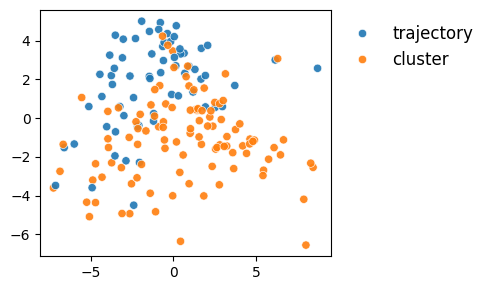

<Figure size 640x480 with 0 Axes>

In [14]:
import seaborn as sns
from diversity_curves.clustering_performance import compute_clustering_scores_resample, compute_clustering_scores

proj = arrays['emb_spread_shortest_pathsspread_emb_spread_features_scaled_pca']

plt.figure(figsize=(5,3))
sns.scatterplot(x=proj[:, 0], y=proj[:, 1], hue=traj_types_vals2, palette="tab10", alpha=0.9)
plt.legend(bbox_to_anchor=(1, 1), frameon=False, fontsize=12)
plt.tight_layout()
plt.show()
plt.savefig("./plots/sc_pca.pdf")

Plot the diversity curves themselves for different choices of metrics. This is Figure S.7 in our manuscript.

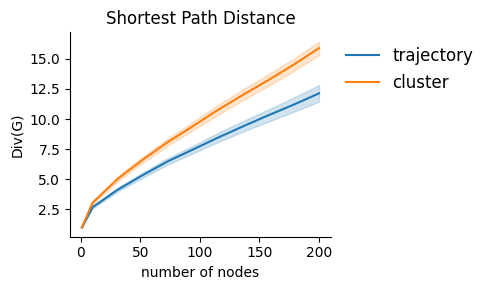

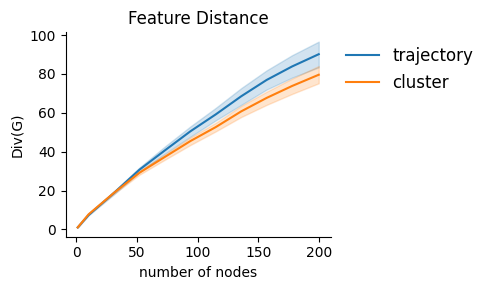

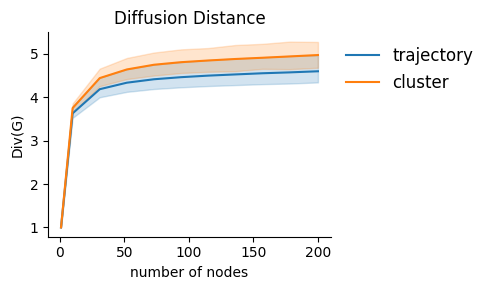

In [15]:
for i, j in enumerate(["emb_spread_shortest_paths", "emb_spread_features", "emb_spread_diffusion_distance"]):
    fun_df2 = pd.DataFrame(arrays[j]).copy()
    fun_df2.columns = [1] +list(np.linspace(10, 200, 10, dtype=int))
    fun_df2["dataset"] = names
    fun_df2["trajectory_type"] = traj_types_vals2
    df_long2 = (
    fun_df2.reset_index()
        .rename(columns={"index": "graph_index"})
        .melt(
            id_vars=["dataset", "graph_index", "trajectory_type"],
            value_vars=[c for c in fun_df2.columns if c not in ("dataset", "trajectory_type")],
            var_name="n_nodes",
            value_name="spread"
        )
    )
    df_long2["n_nodes"] = df_long2["n_nodes"].astype(int)
    import seaborn as sns
    import matplotlib.pyplot as plt
    plt.figure(figsize=(5,3))
    sns.lineplot(data=df_long2, x="n_nodes", y="spread", hue="trajectory_type")
    sns.despine()
    plt.legend(bbox_to_anchor=(1, 1), frameon=False, fontsize=12)
    plt.xlabel("number of nodes")
    plt.ylabel("Div(G)")
    nice_names = ["Shortest Path Distance", "Feature Distance", "Diffusion Distance"]
    plt.title(nice_names[i])
    plt.tight_layout()
    plt.savefig(f"./plots/sc_{j}_lineplot.pdf")
    plt.show()

# Distinguishing cluster- or trajectory-like single-cell graphs

Decide on the list of methods to compare.

In [16]:
items = [
    "emb_spread_shortest_pathsspread_emb_spread_diffusion_distancespread_emb_spread_features",
    "emb_spread_diffusion_distancespread_emb_spread_features",
    "emb_spread_shortest_pathsspread_emb_spread_diffusion_distance",
    "emb_spread_shortest_pathsspread_emb_spread_features",
    "emb_spread_diffusion_distance",
    "emb_spread_features",
    "emb_spread_shortest_paths",
    "netlsd",
    "feather",
    "spectral_zoo_moments",
    "graph2",
    "scores",
    "scores_1",
    "scores_4",
    "scores_2",
    "landscape",
    "scores_3",
    "scores_0",
    "kernel_pyramid_match",
    "kernel_weisfeiler_lehman",
    "kernel_shortest_path",
    "kernel_core_framework",
    "kernel_weisfeiler_lehman_optimal_assignment",
    "kernel_neighborhood_hash",
    "toper_all_sub",
    "toper_olricci_sub",
    "toper_popularity_sub",
    "toper_forricci_sub",
    "toper_degree_sub",
    "toper_closeness_sub",
]

## Classification results on all datasets

Run 5-fold repeated stratified cross-validation as described in the paper to get the results reported in Table S.6 and Table 3.

In [17]:
accs_df=[]
accs_df_balanced=[]
aurocs_df=[]
seeds = [50, 58, 64, 66, 68]
for seed in seeds:
    all_accs = {}
    all_accs_balanced = {}
    all_aurocs = {}
    for key in arrays.keys():
        if key in items:
            print("")
            print(key, arrays[key].shape)
            X = arrays[key]
            random.seed(seed)
            np.random.seed(seed)
            precomputed=(X.shape[0] == X.shape[1])
            if precomputed:
                X=-X+X.max()
            test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=lables_t, precomputed=precomputed, outer_k=5, holdout_test_size=0.2, stratify=True, tune=True, seed=seed, scale=False)
            all_accs[key] = test_accs
            all_accs_balanced[key] = test_accs_balanced
            all_aurocs[key] = test_aurocs
            if "spread" in key:
                test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=lables_t, precomputed=precomputed, outer_k=5, holdout_test_size=0.2, stratify=True, tune=True, seed=seed, scale=True)
                all_accs[key+"_rescaled"] = test_accs
                all_accs_balanced[key+"_rescaled"] = test_accs_balanced
                all_aurocs[key+"_rescaled"] = test_aurocs
    accs_df.append(pd.DataFrame(all_accs))
    accs_df_balanced.append(pd.DataFrame(all_accs_balanced))
    aurocs_df.append(pd.DataFrame(all_aurocs))
accs_df_full = accs_df.copy()
accs_df_balanced_full = accs_df_balanced.copy()
aurocs_df_full = aurocs_df.copy()


scores (169, 5)


Fold 0: test accuracy = 0.7941, test balanced accuracy = 0.7941, test AUROC = 0.7941
Fold 1: test accuracy = 0.7353, test balanced accuracy = 0.7353, test AUROC = 0.7353
Fold 2: test accuracy = 0.5882, test balanced accuracy = 0.5882, test AUROC = 0.5882
Fold 3: test accuracy = 0.6765, test balanced accuracy = 0.6765, test AUROC = 0.6765
Fold 4: test accuracy = 0.7576, test balanced accuracy = 0.7574, test AUROC = 0.7574

Mean test accuracy: 0.7103
Std test accuracy:  0.0720
Mean balanced test accuracy: 0.7103
Std balanced test accuracy:  0.0720
Mean test AUROC: 0.7103
Std test AUROC:  0.0720

scores_0 (169, 1)
Fold 0: test accuracy = 0.5588, test balanced accuracy = 0.5588, test AUROC = 0.5519
Fold 1: test accuracy = 0.5294, test balanced accuracy = 0.5294, test AUROC = 0.4706
Fold 2: test accuracy = 0.4706, test balanced accuracy = 0.4706, test AUROC = 0.4706
Fold 3: test accuracy = 0.5294, test balanced accuracy = 0.5294, test AUROC = 0.5156
Fold 4: test accuracy = 0.5152, test bala

Save the resulting mean accuracies and AUROC scores as well as their standard deviations.

In [18]:
accs_df3 = pd.concat(aurocs_df_full, axis=0)
accs_df3 = accs_df3.T.mean(axis=1)
accs_df1 = pd.concat(accs_df_full, axis=0)
accs_df1 = accs_df1.T.mean(axis=1)
accs_df2 = pd.concat(accs_df_balanced_full, axis=0)
accs_df2 = accs_df2.T.mean(axis=1)

all_accs_data = pd.concat([accs_df1, accs_df2, accs_df3], axis=1)
all_accs_data.columns = ["Accuracy", "Balanced Accuracy", "AUROC"]
all_accs_data.to_csv("./accuracies/single_cell_results_knn_mean.csv")
all_accs_data_mean = all_accs_data.copy()

In [19]:
accs_df3 = pd.concat(aurocs_df_full, axis=0)
accs_df3 = accs_df3.T.std(axis=1)
accs_df1 = pd.concat(accs_df_full, axis=0)
accs_df1 = accs_df1.T.std(axis=1)
accs_df2 = pd.concat(accs_df_balanced_full, axis=0)
accs_df2 = accs_df2.T.std(axis=1)

all_accs_data = pd.concat([accs_df1, accs_df2, accs_df3], axis=1)
all_accs_data.columns = ["Accuracy", "Balanced Accuracy", "AUROC"]
all_accs_data.to_csv("./accuracies/single_cell_results_knn_std.csv")
all_accs_data_std = all_accs_data.copy()

In [20]:
combined = all_accs_data_mean.round(3).astype(str) + " ± " + all_accs_data_std.round(3).astype(str)
combined.sort_values("Accuracy", ascending=False).to_csv("./accuracies/single_cell_results_knn_combined.csv")

In [21]:
combined.round(3).sort_values("Accuracy", ascending=False)

,Accuracy,Balanced Accuracy,AUROC
emb_spread_shortest_pathsspread_emb_spread_diffusion_distancespread_emb_spread_features_rescaled,0.766 ± 0.062,0.766 ± 0.062,0.81 ± 0.068
emb_spread_shortest_pathsspread_emb_spread_features_rescaled,0.759 ± 0.077,0.759 ± 0.077,0.808 ± 0.081
emb_spread_diffusion_distancespread_emb_spread_features_rescaled,0.745 ± 0.075,0.744 ± 0.075,0.779 ± 0.081
emb_spread_diffusion_distance_rescaled,0.743 ± 0.061,0.743 ± 0.061,0.786 ± 0.065
emb_spread_diffusion_distance,0.736 ± 0.069,0.736 ± 0.069,0.772 ± 0.08
netlsd,0.731 ± 0.047,0.731 ± 0.048,0.802 ± 0.057
emb_spread_shortest_pathsspread_emb_spread_diffusion_distancespread_emb_spread_features,0.723 ± 0.056,0.723 ± 0.055,0.755 ± 0.061
emb_spread_features_rescaled,0.721 ± 0.075,0.721 ± 0.075,0.759 ± 0.089
emb_spread_shortest_pathsspread_emb_spread_features,0.717 ± 0.059,0.717 ± 0.059,0.754 ± 0.068
scores,0.716 ± 0.053,0.716 ± 0.053,0.76 ± 0.061


## Classification on gold standard single-cell graphs

In [22]:
sub_arrays={}
for key in arrays.keys():
    X = arrays[key]
    sub_arrays[key] = X[bol1.values,:]

In [23]:
lables_t_sub = lables_t[bol1.values]

In [24]:
import warnings
warnings.filterwarnings("ignore")

accs_df=[]
accs_df_balanced=[]
aurocs_df=[]
for seed in seeds:
    all_accs = {}
    all_accs_balanced = {}
    all_aurocs = {}
    for key in sub_arrays.keys():
        if key in items:
            print("")
            print(key, sub_arrays[key].shape)
            X = sub_arrays[key]
            random.seed(seed)
            np.random.seed(seed)
            precomputed=(X.shape[0] == X.shape[1])
            if precomputed:
                X=-X+X.max()
            test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=lables_t_sub, precomputed=precomputed, outer_k=5, holdout_test_size=0.2, stratify=True, tune=True, seed=seed, scale=False)
            all_accs[key] = test_accs
            all_accs_balanced[key] = test_accs_balanced
            all_aurocs[key] = test_aurocs
            #if not precomputed:
            if "spread" in key:
                test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=lables_t_sub, precomputed=precomputed, outer_k=5, holdout_test_size=0.2, stratify=True, tune=True, seed=seed, scale=True)
                all_accs[key+"_rescaled"] = test_accs
                all_accs_balanced[key+"_rescaled"] = test_accs_balanced
                all_aurocs[key+"_rescaled"] = test_aurocs
    accs_df.append(pd.DataFrame(all_accs))
    accs_df_balanced.append(pd.DataFrame(all_accs_balanced))
    aurocs_df.append(pd.DataFrame(all_aurocs))
accs_df_gold = accs_df.copy()
accs_df_balanced_gold = accs_df_balanced.copy()
aurocs_df_gold = aurocs_df.copy()


scores (87, 5)
Fold 0: test accuracy = 0.7778, test balanced accuracy = 0.7500, test AUROC = 0.7500
Fold 1: test accuracy = 0.8333, test balanced accuracy = 0.8333, test AUROC = 0.8333
Fold 2: test accuracy = 0.7647, test balanced accuracy = 0.7750, test AUROC = 0.7750
Fold 3: test accuracy = 0.8235, test balanced accuracy = 0.7000, test AUROC = 0.7000
Fold 4: test accuracy = 0.8824, test balanced accuracy = 0.8583, test AUROC = 0.8917

Mean test accuracy: 0.8163
Std test accuracy:  0.0421
Mean balanced test accuracy: 0.7833
Std balanced test accuracy:  0.0570
Mean test AUROC: 0.7900
Std test AUROC:  0.0665

scores_0 (87, 1)
Fold 0: test accuracy = 0.6667, test balanced accuracy = 0.6250, test AUROC = 0.5764
Fold 1: test accuracy = 0.6667, test balanced accuracy = 0.5833, test AUROC = 0.5833
Fold 2: test accuracy = 0.5882, test balanced accuracy = 0.5333, test AUROC = 0.5000
Fold 3: test accuracy = 0.6471, test balanced accuracy = 0.5167, test AUROC = 0.6500
Fold 4: test accuracy = 0.

In [25]:
accs_df3 = pd.concat(aurocs_df_gold, axis=0)#pd.DataFrame(all_accs)#.to_csv("single_cell_results_knn.csv")
accs_df3 = accs_df3.T.mean(axis=1)
accs_df1 = pd.concat(accs_df_gold, axis=0)#pd.DataFrame(all_accs)#.to_csv("single_cell_results_knn.csv")
accs_df1 = accs_df1.T.mean(axis=1)
accs_df2 = pd.concat(accs_df_balanced_gold, axis=0)#pd.DataFrame(all_accs)#.to_csv("single_cell_results_knn.csv")
accs_df2 = accs_df2.T.mean(axis=1)

all_accs_data = pd.concat([accs_df1, accs_df2, accs_df3], axis=1)
all_accs_data.columns = ["Accuracy", "Balanced Accuracy", "AUROC"]
all_accs_data.to_csv("./accuracies/single_cell_results_knn_mean_gol.csv")
all_accs_data_mean = all_accs_data.copy()

In [26]:
accs_df3 = pd.concat(aurocs_df_gold, axis=0)#pd.DataFrame(all_accs)#.to_csv("single_cell_results_knn.csv")
accs_df3 = accs_df3.T.std(axis=1)
accs_df1 = pd.concat(accs_df_gold, axis=0)#pd.DataFrame(all_accs)#.to_csv("single_cell_results_knn.csv")
accs_df1 = accs_df1.T.std(axis=1)
accs_df2 = pd.concat(accs_df_balanced_gold, axis=0)#pd.DataFrame(all_accs)#.to_csv("single_cell_results_knn.csv")
accs_df2 = accs_df2.T.std(axis=1)

all_accs_data = pd.concat([accs_df1, accs_df2, accs_df3], axis=1)
all_accs_data.columns = ["Accuracy", "Balanced Accuracy", "AUROC"]
all_accs_data.to_csv("./accuracies/single_cell_results_knn_std_gold.csv")
all_accs_data_mstd = all_accs_data.copy()

In [27]:
combined = all_accs_data_mean.round(3).astype(str) + " ± " + all_accs_data_std.round(3).astype(str)
combined.sort_values("Accuracy", ascending=False).to_csv("./accuracies/single_cell_results_knn_combined_gold.csv")

In [28]:
combined.sort_values("Accuracy", ascending=False)

,Accuracy,Balanced Accuracy,AUROC
emb_spread_shortest_pathsspread_emb_spread_features_rescaled,0.86 ± 0.077,0.813 ± 0.077,0.831 ± 0.081
emb_spread_shortest_pathsspread_emb_spread_diffusion_distancespread_emb_spread_features_rescaled,0.86 ± 0.062,0.813 ± 0.062,0.824 ± 0.068
emb_spread_features_rescaled,0.843 ± 0.075,0.794 ± 0.075,0.809 ± 0.089
emb_spread_diffusion_distancespread_emb_spread_features_rescaled,0.834 ± 0.075,0.782 ± 0.075,0.808 ± 0.081
feather,0.83 ± 0.071,0.791 ± 0.071,0.824 ± 0.085
scores_1,0.829 ± 0.058,0.795 ± 0.059,0.83 ± 0.066
emb_spread_shortest_pathsspread_emb_spread_diffusion_distancespread_emb_spread_features,0.826 ± 0.056,0.781 ± 0.055,0.827 ± 0.061
emb_spread_shortest_pathsspread_emb_spread_features,0.823 ± 0.059,0.777 ± 0.059,0.824 ± 0.068
netlsd,0.823 ± 0.047,0.797 ± 0.048,0.848 ± 0.057
spectral_zoo_moments,0.821 ± 0.074,0.775 ± 0.074,0.799 ± 0.095


## Classification results reported by Lim and Qui

Based on the number of all cluster- or trajectory-like datasets correctly or incorrectly classified by the geometric landscape approach by Lim and Qui reported in Figure 6c of their manuscript, simulate the estimated accuracies and AUROC scores across 5-fold repeated cross-validation to compare with our results above. These estimates are further reported as `Lanscape` in Table 3 and Table S.6 of our manuscrpt.

In [29]:
import numpy as np

def simulate_cv_from_cm(tp, fp, fn, tn, n_folds=10):
    """
    Simulates 10-fold Stratified CV results based on a single 
    precomputed confusion matrix.
    """
    # Total samples per class
    total_pos = tp + fn
    total_neg = tn + fp
    
    # Probabilities of the model being correct (per class)
    tpr = tp / total_pos if total_pos > 0 else 0
    tnr = tn / total_neg if total_neg > 0 else 0
    
    # Samples per fold (Stratified)
    fold_pos_count = total_pos // n_folds
    fold_neg_count = total_neg // n_folds
    
    acc_list, bal_acc_list = [], []

    for _ in range(n_folds):
        # Simulate results for this fold using Binomial distribution
        # fold_tp = number of successes in 'fold_pos_count' trials
        fold_tp = np.random.binomial(fold_pos_count, tpr)
        fold_tn = np.random.binomial(fold_neg_count, tnr)
        
        # Derived counts for the fold
        fold_fn = fold_pos_count - fold_tp
        fold_fp = fold_neg_count - fold_tn
        
        # Calculate Metrics
        total = fold_pos_count + fold_neg_count
        acc = (fold_tp + fold_tn) / total
        
        sens = fold_tp / fold_pos_count if fold_pos_count > 0 else 0
        spec = fold_tn / fold_neg_count if fold_neg_count > 0 else 0
        bal_acc = (sens + spec) / 2
        
        acc_list.append(acc)
        bal_acc_list.append(bal_acc)

    # Compile results
    metrics = {
        "Accuracy": acc_list,
        "Balanced Accuracy": bal_acc_list,
        "AUROC": bal_acc_list 
    }

    print(f"{'Metric':<20} | {'Mean':<10} | {'Std Dev':<10}")
    print("-" * 45)
    for name, scores in metrics.items():
        print(f"{name:<20} | {np.mean(scores):<10.4f} | {np.std(scores, ddof=1):<10.4f}")

# --- Example Usage ---
# Let's say your precomputed matrix is:
# TP: 150, FP: 40, FN: 50, TN: 760 (Total 1000)
np.random.seed(44)
simulate_cv_from_cm(63, 22, 51, 33, 5)

Metric               | Mean       | Std Dev   
---------------------------------------------
Accuracy             | 0.5697     | 0.0254    
Balanced Accuracy    | 0.5864     | 0.0373    
AUROC                | 0.5864     | 0.0373    
